<a href="https://colab.research.google.com/github/vincentmartin/tp-initiation-llm-student-version/blob/main/TP_initiation_llm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP d'initiation aux LLM

Dans ce TP, vous allez apprendre les bases de l'IA générative en manipulant et en contrôlant un LLM **open-weight** exécuté localement sur le GPU de Colab : aucun compte payant ni clé d'API n'est nécessaire.

En sortie de ce TP, vous serez capable de :
- Expliquer ce qu'est un token, un tokenizer, un *chat template* et une fenêtre de contexte
- Observer ce que calcule réellement un LLM : une distribution de probabilité sur le token suivant
- Distinguer un modèle *base* d'un modèle *instruct*, et utiliser un modèle de raisonnement (*thinking*)
- Appliquer les techniques de prompt engineering : system prompt, zero-shot, one-shot, few-shot
- Contrôler la génération (température, top-k, top-p, échantillonnage)
- Évaluer des sorties de LLM (ROUGE, LLM-as-a-judge)
- Obtenir des sorties structurées (JSON validé par Pydantic)
- Utiliser un LLM pour structurer des données et alimenter une base, ou pour classer des textes à partir de ses probabilités

**Modèle utilisé** : [Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B) (Alibaba, licence Apache 2.0). Petit, multilingue, avec un mode raisonnement activable : il tient sans problème sur le GPU T4 gratuit de Colab.

### Instructions pour l'exécution sur Google Colab

Aller dans `Exécution -> Modifier le type d'exécution` puis sélectionner `T4 GPU`.

![Colab GPU](https://raw.githubusercontent.com/vincentmartin/tp-initiation-llm-student-version/main/resources/colab_gpu.png "T4-GPU")

**Pas de GPU disponible sur Colab ?** (quota atteint, heure de pointe) : utilisez [Kaggle Notebooks](https://www.kaggle.com/code), gratuit avec environ 30 h de GPU par semaine (`Settings -> Accelerator -> GPU T4 x2`, et activer `Internet` après vérification du compte par téléphone). Importez ce notebook via `File -> Import Notebook`.

**Assistants IA** : vous pouvez utiliser l'assistant intégré à Colab, mais vous devez être capables d'expliquer **chaque ligne** du code que vous rendez. Les questions d'analyse comptent autant que le code.

**Indices** : la plupart des exercices sont suivis d'indices repliables (💡, cliquez pour les ouvrir). Cherchez d'abord par vous-mêmes, puis ouvrez-les **un par un** : ils vont de la simple piste au squelette de code.



## 0. Installation et configuration

Colab fournit déjà `torch` : **ne le réinstallez pas**, cela casserait la compatibilité avec CUDA. Nous mettons simplement à jour les bibliothèques Hugging Face :
- **transformers** : chargement et utilisation des modèles de type Transformer
- **accelerate** : placement automatique du modèle sur le GPU
- **datasets** : téléchargement de jeux de données depuis le Hub Hugging Face
- **evaluate** / **rouge_score** : métriques d'évaluation

In [ ]:
# Déjà installé dans le .venv sur Mac ; sur Colab, cette ligne installe ce qui manque.
%pip install -q transformers accelerate datasets evaluate rouge_score


**Remarque** : si l'import ci-dessous échoue juste après l'installation, redémarrez la session (`Exécution -> Redémarrer la session`) puis relancez les cellules à partir d'ici.

In [1]:
import gc
import json
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

print(f"torch {torch.__version__} | transformers {transformers.__version__}")

if torch.cuda.is_available():
    DEVICE = "cuda"
    print("GPU :", torch.cuda.get_device_name(0))
    # Le T4 (architecture Turing, compute capability 7.5) ne gère pas nativement le bfloat16 :
    # on utilise float16 sur ce type de GPU, bfloat16 sur les GPU récents (Ampere et +).
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
elif torch.backends.mps.is_available():
    DEVICE = "mps"  # GPU Apple Silicon (Mac M1/M2/M3...)
    print("GPU Apple Silicon (MPS)")
    DTYPE = torch.float16
else:
    DEVICE = "cpu"
    print("ATTENTION : pas de GPU, l'exécution sera très lente. Vérifiez le type d'exécution.")
    DTYPE = torch.float32


def free_memory():
    """Libère la mémoire GPU (CUDA ou MPS)."""
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


set_seed(42)

torch 2.15.0 | transformers 5.23.0
GPU Apple Silicon (MPS)


## 1. Tokenisation

Un LLM ne manipule pas des caractères ni des mots, mais des **tokens** : des morceaux de mots issus d'un vocabulaire fixe (environ 150 000 tokens pour Qwen3). Le **tokenizer** convertit le texte en une suite d'identifiants entiers (*ids*) et inversement.

Chargeons le tokenizer de notre modèle.

In [5]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(f"Taille du vocabulaire : {len(tokenizer)}")

Taille du vocabulaire : 151669


**Exercice 1** : en vous aidant de la [documentation des tokenizers](https://huggingface.co/docs/transformers/main_classes/tokenizer) :
- encoder la phrase en une liste d'ids et l'afficher ;
- afficher les tokens correspondant à ces ids (méthode `convert_ids_to_tokens`) ;
- décoder la liste d'ids pour retrouver la phrase.

<details>
<summary>💡 Indice 1 : encoder</summary>

Le tokenizer s'appelle comme une fonction : `tokenizer(sentence)` renvoie un dictionnaire. Affichez-le : les ids sont sous la clé `"input_ids"`.

</details>

<details>
<summary>💡 Indice 2 : afficher les tokens et décoder</summary>

- `tokenizer.convert_ids_to_tokens(liste_d_ids)` renvoie les tokens sous forme de chaînes ;
- `tokenizer.decode(liste_d_ids)` fait l'opération inverse de l'encodage.

</details>

In [6]:
sentence = "Que peux-tu me dire sur les LLMs ?"


encoded = tokenizer(sentence)
ids = encoded["input_ids"]
print("IDs :", ids)


tokens = tokenizer.convert_ids_to_tokens(ids)
print("Tokens :", tokens)


decoded = tokenizer.decode(ids)
print("Décodé :", decoded)
assert decoded == sentence

IDs : [25776, 93197, 2385, 84, 752, 13207, 1729, 3541, 444, 10994, 82, 937]
Tokens : ['Que', 'Ġpeux', '-t', 'u', 'Ġme', 'Ġdire', 'Ġsur', 'Ġles', 'ĠL', 'LM', 's', 'Ġ?']
Décodé : Que peux-tu me dire sur les LLMs ?


Le caractère `Ġ` représente un espace : il fait partie du token qui le suit.

**Exercice 2** : comparons le nombre de tokens nécessaires pour une même phrase en français et en anglais, avec le tokenizer de Qwen3 et celui de `flan-t5`, le modèle utilisé dans les versions précédentes de ce TP (2022). Écrire une fonction `count_tokens(tok, text)` puis compléter le tableau.

<details>
<summary>💡 Indice 1 : compter les tokens</summary>

Le nombre de tokens est simplement la longueur de la liste d'ids obtenue à l'exercice 1. La fonction tient en une ligne et doit utiliser le paramètre `tok` (et non la variable globale `tokenizer`) : elle est appelée avec les deux tokenizers.

</details>

<details>
<summary>💡 Indice 2 : une comparaison équitable</summary>

Certains tokenizers ajoutent des tokens spéciaux qui ne correspondent à aucun mot du texte (par exemple `</s>` en fin de séquence pour `flan-t5`). Passez `add_special_tokens=False` au tokenizer pour ne compter que les tokens du texte.

</details>

In [ ]:
old_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-base")

sentences = {
    "fr": "L'intelligence artificielle générative transforme profondément le développement logiciel.",
    "en": "Generative artificial intelligence is profoundly transforming software development.",
}


def count_tokens(tok, text):
    return len(tok(text, add_special_tokens=False)["input_ids"])

pd.DataFrame({
    name: {lang: count_tokens(tok, text) for lang, text in sentences.items()}
    for name, tok in {"Qwen3": tokenizer, "flan-t5": old_tokenizer}.items()
})

,Qwen3,flan-t5
fr,19,17
en,10,13


**Question** : pourquoi le français demande-t-il plus de tokens que l'anglais ? Quelles conséquences pratiques cela a-t-il (coût d'une API facturée au token, vitesse, fenêtre de contexte) ? Affichez aussi les tokens de la phrase française avec `flan-t5` : que remarquez-vous ?

<details>
<summary>💡 Indice</summary>

Pour voir les tokens de `flan-t5` : `old_tokenizer.convert_ids_to_tokens(old_tokenizer(sentences["fr"])["input_ids"])`. Regardez ce que deviennent les lettres accentuées.

</details>

✍️ **Votre réponse :**
Le français demande plus de tokens que l’anglais parce que les tokenizers sont surtout entraînés sur des textes anglais. Les mots anglais courants ont leur propre token, alors que les mots français, plus longs et avec des accents, sont découpés en plusieurs morceaux. Ce problème est plus marqué avec flan-t5, dont le vocabulaire est centré sur l’anglais.

Conséquences pratiques :

Coût : une API facturée au token coûte plus cher pour un texte en français.  
Contexte : la fenêtre de contexte se remplit plus vite, donc on peut mettre moins de texte dans un prompt.  
Vitesse : la génération est plus lente, car il y a plus de tokens à produire.


### Le chat template

Les modèles conversationnels sont entraînés sur des conversations mises en forme avec des **tokens spéciaux** qui délimitent les rôles (`system`, `user`, `assistant`). Chaque famille de modèles a son propre format : le **chat template**, fourni avec le tokenizer. On ne l'écrit jamais à la main, on utilise `apply_chat_template`.

In [21]:
messages = [
    {"role": "system", "content": "Tu es un assistant concis qui répond en français."},
    {"role": "user", "content": "Quelle est la capitale de la France ?"},
]

prompt_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,              # renvoie le texte plutôt que les ids
    add_generation_prompt=True,  # ajoute le début du tour de l'assistant
    enable_thinking=False,       # désactive le mode raisonnement (voir partie 4)
)
print(prompt_text)

<|im_start|>system
Tu es un assistant concis qui répond en français.<|im_end|>
<|im_start|>user
Quelle est la capitale de la France ?<|im_end|>
<|im_start|>assistant
<think>

</think>




**Question** : à quoi servent les tokens `<|im_start|>` et `<|im_end|>` ? Pourquoi le template se termine-t-il par `<|im_start|>assistant` ?

✍️ **Votre réponse :**

Ce sont des tokens spéciaux qui délimitent les différents rôles (system, user, assistant) et leurs messages dans la conversation : `<|im_start|>` marque le début d’un tour de parole et `<|im_end|>` sa fin.

Le template se termine par `<|im_start|>assistant` car c’est au tour du modèle de fournir une réponse. Le modèle continue le texte à partir de là, et quand il a terminé, il génère le token `<|im_end|>`.

### La fenêtre de contexte

Un modèle ne peut traiter qu'un nombre limité de tokens à la fois : c'est sa **fenêtre de contexte**.

In [14]:
print(f"flan-t5 : {old_tokenizer.model_max_length} tokens")
print(f"Qwen3   : {tokenizer.model_max_length} tokens")

del old_tokenizer

flan-t5 : 512 tokens
Qwen3   : 131072 tokens


Gardez ces chiffres en tête : nous verrons dans la partie 4 que la limite de 512 tokens de `flan-t5` faussait une partie des conclusions des anciennes versions de ce TP.

## 2. Sous le capot : prédire le token suivant

Chargeons le modèle sur le GPU (environ 3,5 Go en float16).

In [15]:
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, device_map=DEVICE)
print(f"Mémoire occupée par le modèle : {model.get_memory_footprint() / 1e9:.1f} Go")

W1116 11:17:58.211000 14569 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Mémoire occupée par le modèle : 3.4 Go


Un LLM *causal* fait **une seule chose** : à partir d'une suite de tokens, il calcule un score (*logit*) pour chacun des ~150 000 tokens du vocabulaire. Un `softmax` transforme ces scores en probabilités pour le **token suivant**.

**Exercice 3** : compléter la fonction `next_token_distribution` qui renvoie le vecteur de probabilités du token suivant. Indications :
- `model(input_ids=...)` renvoie un objet dont l'attribut `logits` a la forme `(batch, longueur_séquence, taille_vocabulaire)` ;
- seuls les logits de la **dernière position** nous intéressent ;
- la température divise les logits **avant** le softmax.

<details>
<summary>💡 Indice 1 : les étapes</summary>

1. Encoder `text` en un **tenseur PyTorch** (et non une liste) : paramètre `return_tensors="pt"`. On obtient des ids de forme `(1, longueur_séquence)` : un batch d'une seule phrase.
2. Déplacer ce tenseur sur le même device que le modèle (le GPU) : `.to(model.device)`.
3. Appeler le modèle et récupérer `.logits`.
4. Garder les logits de la dernière position, diviser par la température, appliquer `torch.softmax`.

</details>

<details>
<summary>💡 Indice 2 : pourquoi la dernière position ?</summary>

Le modèle calcule une prédiction **pour chaque position** : à la position `t`, il prédit le token `t+1` en ne voyant que les tokens `0..t`. Avec `"La capitale de la France est"` :

| position | le modèle a vu | il prédit le token après... |
|---|---|---|
| 0 | `La` | « La » (déjà connu) |
| 1 | `La capitale` | « capitale » (déjà connu) |
| ... | ... | ... |
| dernière | toute la phrase | « est » : **c'est ce qu'on cherche** |

Les autres positions servent pendant l'entraînement (on calcule l'erreur sur toutes les positions en parallèle), pas pour générer.

Un **logit** est un score brut (positif ou négatif, non borné) attribué à chaque token du vocabulaire. Le softmax $p_i = e^{z_i} / \sum_j e^{z_j}$ le transforme en probabilité.

</details>

<details>
<summary>💡 Indice 3 : indexation et détails pratiques</summary>

- `logits[0, -1]` : premier (et seul) élément du batch, dernière position. On obtient un vecteur de taille `taille_vocabulaire`.
- `torch.softmax(x, dim=-1)` normalise selon la dernière dimension.
- Entourez l'appel au modèle de `with torch.no_grad():` : on ne fait pas d'entraînement, inutile de stocker de quoi calculer les gradients (gain de mémoire et de temps).
- Les logits sont en float16 : `.float()` les convertit en float32 pour un softmax plus précis.
- Vérification : `next_token_distribution(text).sum()` doit valoir environ 1.

</details>

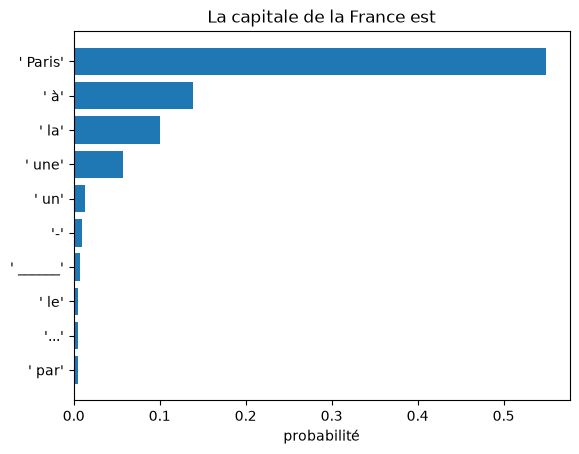

In [17]:
def next_token_distribution(text, temperature=1.0):
    """Renvoie le vecteur des probabilités du token suivant `text`."""
    inputs = tokenizer(text, return_tensors="pt").to(model.device)

    with torch.no_grad():
        logits = model(**inputs).logits

    last_logits = logits[0, -1].float() / temperature
    return torch.softmax(last_logits, dim=-1)


def plot_top_tokens(probs, k=10, title=""):
    """Affiche les k tokens les plus probables sous forme de diagramme en barres."""
    top = torch.topk(probs, k)
    labels = [repr(tokenizer.decode(i)) for i in top.indices]
    plt.barh(labels[::-1], top.values.cpu().numpy()[::-1])
    plt.xlabel("probabilité")
    plt.title(title)
    plt.show()


text = "La capitale de la France est"
plot_top_tokens(next_token_distribution(text), title=text)

**Exercice 4** : générer du texte, c'est appeler le modèle en boucle. Écrire la fonction `greedy_decode` qui, à chaque étape, choisit le token le plus probable (*greedy decoding*), l'ajoute à la séquence et recommence, jusqu'à `max_new_tokens` ou jusqu'au token de fin. Comparer avec le résultat de `model.generate(..., do_sample=False)`.

<details>
<summary>💡 Indice 1 : l'algorithme</summary>

```
encoder le texte -> input_ids, de forme (1, L)
mémoriser la longueur du prompt
répéter max_new_tokens fois :
    calculer les logits de la dernière position (comme à l'exercice 3)
    next_id <- indice du logit maximal
    ajouter next_id à la fin de input_ids
    si next_id est un token de fin : sortir de la boucle
décoder uniquement les tokens ajoutés
```
Le softmax est inutile ici : il ne change pas l'ordre des scores, donc le token de plus grand logit est aussi le plus probable.

</details>

<details>
<summary>💡 Indice 2 : les fonctions PyTorch utiles</summary>

- `logits.argmax()` : indice du maximum (tenseur à 0 dimension).
- `torch.cat([a, b], dim=1)` : concatène deux tenseurs selon la dimension des positions. `b` doit avoir la même forme que `a` sauf sur cette dimension, soit `(1, 1)` : `next_id.view(1, 1)`.
- `next_id.item()` convertit le tenseur en entier Python, pour tester `in EOS_IDS`.
- `input_ids[0, prompt_length:]` : les tokens générés seulement ; `tokenizer.decode(..., skip_special_tokens=True)` retire `<|im_end|>`.

</details>

In [20]:
EOS_IDS = model.generation_config.eos_token_id  # liste des ids qui terminent la génération


def greedy_decode(text, max_new_tokens=30):
    input_ids = tokenizer(text, return_tensors="pt")["input_ids"].to(model.device)
    prompt_length = input_ids.shape[1]

    for _ in range(max_new_tokens):
        with torch.no_grad():
            logits = model(input_ids=input_ids).logits

        next_id = logits[0, -1].argmax()

        input_ids = torch.cat([input_ids, next_id.view(1, 1)], dim=1)

        if next_id.item() in EOS_IDS:
            break

    return tokenizer.decode(input_ids[0, prompt_length:], skip_special_tokens=True)


start = time.perf_counter()
print("Notre boucle    :", repr(greedy_decode(prompt_text)), f"({time.perf_counter() - start:.1f} s)")

inputs = tokenizer(prompt_text, return_tensors="pt").to(model.device)
start = time.perf_counter()
output_ids = model.generate(**inputs, max_new_tokens=30, do_sample=False)
reference = tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print("model.generate  :", repr(reference), f"({time.perf_counter() - start:.1f} s)")

Notre boucle    : 'La capitale de la France est Paris.' (2.7 s)
model.generate  : 'La capitale de la France est Paris.' (0.8 s)


**Question** : les deux sorties sont (normalement) identiques, mais `model.generate` est plus rapide. Notre boucle recalcule tout depuis le début à chaque token : quelle optimisation `generate` met-elle en place ? (indice : *KV cache*)

✍️ **Votre réponse :**

Dans notre boucle on recalcule tout le prompt a chaque token ce qui prend du temps alors que `generate` stocke dans le cache ce qui a déjà été calculer

**Exercice 5** : visualiser la distribution du token suivant pour des températures de 0.2, 1.0 et 2.0. Comment la température modifie-t-elle la distribution ? Quelle valeur choisir pour une tâche factuelle ? Pour de l'écriture créative ?

<details>
<summary>💡 Indice</summary>

Une simple boucle sur les températures suffit : réutilisez `next_token_distribution(text, temperature)` et `plot_top_tokens(...)`, en indiquant la température dans le titre. Pour l'analyse, comparez la probabilité du token le plus probable d'un graphique à l'autre.

</details>

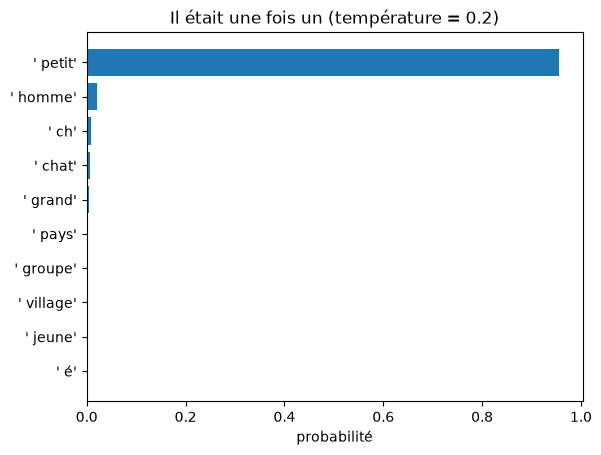

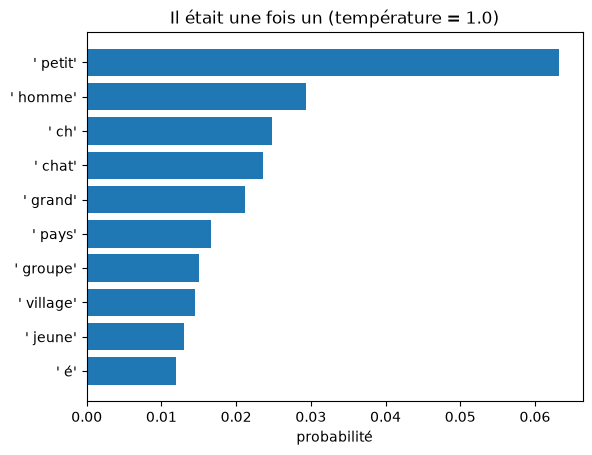

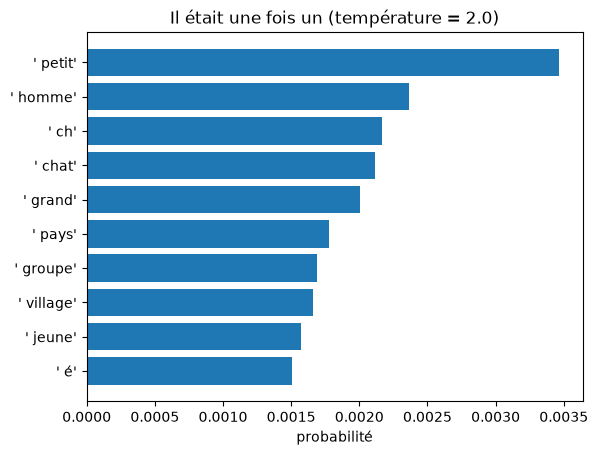

In [22]:
text = "Il était une fois un"

for temperature in [0.2, 1.0, 2.0]:
    probs = next_token_distribution(text, temperature=temperature)
    plot_top_tokens(probs, title=f"{text} (température = {temperature})")

✍️ **Votre réponse :**

La température divise les logits avant le softmax. Une température basse (0.2) accentue les écarts : le token le plus probable écrase les autres et le modèle devient quasi déterministe. Une température haute (2.0) aplatit la distribution : les tokens deviennent presque équiprobables, donc la génération est plus variée mais aussi plus incohérente. À 1.0, on garde la distribution apprise par le modèle.

## 3. Modèle *base* vs modèle *instruct*

Un LLM est construit en deux grandes étapes :
1. le **pré-entraînement** sur des milliers de milliards de tokens de texte brut : on obtient un modèle **base** qui sait compléter du texte ;
2. le **post-entraînement** (*instruction tuning*, puis apprentissage par renforcement) sur des conversations : on obtient un modèle **instruct** (ou *chat*) qui suit des consignes.

Comparons les deux versions de Qwen3-1.7B sur la même question.

In [23]:
base_model = AutoModelForCausalLM.from_pretrained(f"{MODEL_NAME}-Base", dtype=DTYPE, device_map=DEVICE)

question = "Quelle est la capitale de la France ?"

inputs = tokenizer(question, return_tensors="pt").to(base_model.device)
output_ids = base_model.generate(**inputs, max_new_tokens=60, do_sample=False)
print("BASE, texte brut :\n", tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True))

chat_text = tokenizer.apply_chat_template(
    [{"role": "user", "content": question}], tokenize=False, add_generation_prompt=True, enable_thinking=False
)
inputs = tokenizer(chat_text, return_tensors="pt").to(model.device)
output_ids = model.generate(**inputs, max_new_tokens=60, do_sample=False)
print("\nINSTRUCT, chat template :\n", tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True))

# Libérons la mémoire GPU : nous n'utiliserons plus le modèle base.
del base_model
free_memory()

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

BASE, texte brut :
  Quel est le pays le plus peuplé du monde ? Quel est le pays le plus peuplé de l'Europe ? Quel est le pays le plus peuplé du monde ? Quel est le pays le plus peuplé de l'Europe ? Quel est le

INSTRUCT, chat template :
 La capitale de la France est **Paris**.


**Question** : décrivez le comportement du modèle base. Pourquoi « continue »-t-il le texte au lieu de répondre ?

✍️ **Votre réponse :**

Le modèle base ne répond pas à la question, il la continue : il enchaîne d’autres questions du même type (« Quel est le pays le plus peuplé du monde ? ... ») et se répète. Il continue le texte parce qu’il a seulement été entraîné à prédire le token suivant, pas à répondre à des questions. Le modèle instruct, lui, a été entraîné en plus sur des conversations, donc il répond directement « La capitale de la France est Paris ».

## 4. Prompt engineering

### Une fonction de génération réutilisable

Pour ne pas répéter le même code à chaque cellule, écrivons une fonction de génération.

**Exercice 6** : compléter la fonction `generate` qui :
- applique le chat template à la liste de `messages` (avec `add_generation_prompt=True`, `enable_thinking=enable_thinking`, `return_tensors="pt"` et `return_dict=True`) et place le résultat sur le device du modèle ;
- appelle `model.generate` en lui transmettant `max_new_tokens` et les paramètres supplémentaires `**gen_kwargs` ;
- renvoie uniquement le texte **généré** (sans le prompt), sans tokens spéciaux et sans espaces superflus.

<details>
<summary>💡 Indice 1 : un exemple déjà présent</summary>

La cellule de l'exercice 4 qui appelle `model.generate` fait presque tout ce qui est demandé : relisez comment elle appelle `generate` et comment elle ne garde que les tokens générés.

</details>

<details>
<summary>💡 Indice 2 : ce que renvoient les fonctions</summary>

- Avec `return_dict=True` et `return_tensors="pt"`, `apply_chat_template` renvoie un dictionnaire (`input_ids`, `attention_mask`) de tenseurs. On le déplace sur le GPU avec `.to(model.device)` et on le passe tel quel à `model.generate(**inputs, ...)`.
- `model.generate` renvoie **le prompt suivi de la réponse** : un tenseur de forme `(1, longueur_prompt + longueur_générée)`. La longueur du prompt est `inputs["input_ids"].shape[1]`.
- `**gen_kwargs` se transmet tel quel : `model.generate(..., **gen_kwargs)`.
- `.strip()` retire les espaces et sauts de ligne au début et à la fin.

</details>

In [24]:
def generate(messages, max_new_tokens=256, enable_thinking=False, **gen_kwargs):
    """Génère la réponse de l'assistant à une liste de messages au format chat."""
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        enable_thinking=enable_thinking,
        return_tensors="pt",
        return_dict=True,
    ).to(model.device)

    output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, **gen_kwargs)

    prompt_length = inputs["input_ids"].shape[1]
    return tokenizer.decode(output_ids[0, prompt_length:], skip_special_tokens=True).strip()


# Vérification
answer = generate([{"role": "user", "content": "Quelle est la capitale de l'Italie ? Réponds en un mot."}], do_sample=False)
print(answer)
assert answer, "La réponse est vide."
assert "Réponds en un mot" not in answer, "La réponse contient le prompt : ne décodez que les tokens générés."
assert "<|im_end|>" not in answer, "La réponse contient des tokens spéciaux."

Rome.


### Résumé de dialogues

Nous allons utiliser le LLM pour résumer des dialogues du dataset [DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum), qui fournit pour chaque dialogue un résumé écrit par un humain.

In [25]:
dataset = load_dataset("knkarthick/dialogsum")
dataset

README.md:   0%|          | 0.00/4.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 11.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/12460 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})

In [26]:
example_indices = [40, 200]
dash_line = "-" * 100

for index in example_indices:
    example = dataset["test"][index]
    print(dash_line)
    print(f"DIALOGUE {index} :\n{example['dialogue']}")
    print(dash_line)
    print(f"RÉSUMÉ HUMAIN :\n{example['summary']}\n")

----------------------------------------------------------------------------------------------------
DIALOGUE 40 :
#Person1#: What time is it, Tom?
#Person2#: Just a minute. It's ten to nine by my watch.
#Person1#: Is it? I had no idea it was so late. I must be off now.
#Person2#: What's the hurry?
#Person1#: I must catch the nine-thirty train.
#Person2#: You've plenty of time yet. The railway station is very close. It won't take more than twenty minutes to get there.
----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# is in a hurry to catch a train. Tom tells #Person1# there is plenty of time.

----------------------------------------------------------------------------------------------------
DIALOGUE 200 :
#Person1#: Have you considered upgrading your system?
#Person2#: Yes, but I'm not sure what exactly I would need.
#Person1#: You could consider adding a painting program to your software. It would allow you

Tentons une première approche : envoyer le dialogue seul, sans aucune consigne.

In [27]:
for index in example_indices:
    dialogue = dataset["test"][index]["dialogue"]
    output = generate([{"role": "user", "content": dialogue}], max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][index]['summary']}")
    print(f"\nSORTIE DU LLM SANS CONSIGNE :\n{output}\n")

----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# is in a hurry to catch a train. Tom tells #Person1# there is plenty of time.

SORTIE DU LLM SANS CONSIGNE :
Let's break down the timeline based on the conversation:

---

### **Person2** says:  
> "It's ten to nine by my watch."

This means **9:50 PM** is the current time.

---

### **Person1** says:  
> "I must catch the nine-thirty train."

A **nine-thirty train** is **9:30 PM**.

---

### **Person2** says:  
> "You've plenty of time yet. The

----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# teaches #Person2# how to upgrade software and hardware in #Person2#'s system.

SORTIE DU LLM SANS CONSIGNE :
That conversation is a great example of how people can discuss upgrading their systems in a natural, conversational way. Here's a summary and a more structured version of the interaction:

**Question** : est-ce un bon résumé ? Pourquoi ?

✍️ **Votre réponse :**

Non, ce n’est pas un bon résumé. Sans consigne, le modèle ne sait pas qu’on veut un résumé : il détaille le dialogue réplique par réplique (« Person2 says... », « Person1 says... ») avec une mise en forme lourde (titres, citations, séparateurs). La sortie est très longue, elle est coupée au bout de 100 tokens et elle se perd dans des détails (l’heure, le train) au lieu de donner l’essentiel.

Le résumé humain tient en deux phrases courtes : « #Person1# est pressé de prendre un train, Tom lui dit qu’il a largement le temps ». Il faut donc donner une consigne au modèle (system prompt) pour qu’il produise un résumé court, dans le bon style.

### 4.1 Zero-shot

Ajoutons une consigne dans un **system prompt**, qui définit le rôle et le comportement de l'assistant pour toute la conversation. Fournir seulement une consigne, sans exemple, s'appelle l'inférence **zero-shot**.

In [28]:
SYSTEM_PROMPT = (
    "You summarize dialogues. Write a short summary (one or two sentences) in English, "
    "in the third person, focusing on the key points."
)

for index in example_indices:
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": dataset["test"][index]["dialogue"]},
    ]
    output = generate(messages, max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][index]['summary']}")
    print(f"\nRÉSUMÉ ZERO-SHOT :\n{output}\n")

----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# is in a hurry to catch a train. Tom tells #Person1# there is plenty of time.

RÉSUMÉ ZERO-SHOT :
Tom asks what time it is, and Person2 replies that it's ten to nine. Tom is surprised and says he must catch the nine-thirty train, but Person2 insists he has plenty of time and the station is close.

----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# teaches #Person2# how to upgrade software and hardware in #Person2#'s system.

RÉSUMÉ ZERO-SHOT :
Person2 considers upgrading their system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software requirements.



C'est bien mieux ! Mais le style ne correspond pas encore à celui des résumés humains (qui désignent par exemple les personnes par `#Person1#`). Montrons des exemples au modèle.

### 4.2 One-shot et few-shot

L'inférence **one-shot** et **few-shot** consiste à fournir au modèle un ou plusieurs exemples complets (dialogue, résumé) avant le dialogue à traiter. C'est l'**apprentissage en contexte** (*in-context learning*) : le modèle s'adapte à la tâche sans modifier ses poids.

Avec un modèle conversationnel, chaque exemple est représenté par un **tour de conversation** : un message `user` (le dialogue) suivi d'un message `assistant` (le résumé attendu).

Les exemples sont tirés du split `train` et l'évaluation se fait sur le split `test` : on ne doit jamais montrer au modèle les données sur lesquelles on l'évalue.

**Exercice 7** : compléter la fonction `make_messages` qui construit la liste de messages : le system prompt, puis un couple (`user`, `assistant`) par exemple de `shots`, puis le dialogue à résumer.

<details>
<summary>💡 Indice 1 : la liste attendue</summary>

Avec 2 exemples, la fonction doit renvoyer :
```python
[
    {"role": "system", "content": system_prompt},
    {"role": "user", "content": "<dialogue de l'exemple 1>"},
    {"role": "assistant", "content": "<résumé de l'exemple 1>"},
    {"role": "user", "content": "<dialogue de l'exemple 2>"},
    {"role": "assistant", "content": "<résumé de l'exemple 2>"},
    {"role": "user", "content": dialogue},
]
```

</details>

<details>
<summary>💡 Indice 2 : parcourir les exemples</summary>

`shots` est une liste ou un `Dataset` Hugging Face : dans les deux cas, `for shot in shots:` donne un dictionnaire par exemple, et le texte s'obtient avec `shot["dialogue"]` et `shot["summary"]`. Vérifiez le résultat avec le chat template affiché sous la cellule : l'exemple doit apparaître avant le dialogue à résumer.

</details>

In [29]:
def make_messages(dialogue, shots=(), system_prompt=SYSTEM_PROMPT):
    """Construit un prompt few-shot. `shots` est une liste d'exemples {"dialogue": ..., "summary": ...}."""
    messages = [{"role": "system", "content": system_prompt}]

    for shot in shots:
        messages.append({"role": "user", "content": shot["dialogue"]})
        messages.append({"role": "assistant", "content": shot["summary"]})

    messages.append({"role": "user", "content": dialogue})
    return messages


one_shot = dataset["train"].select([0])
messages = make_messages(dataset["test"][200]["dialogue"], one_shot)
print(tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False))

<|im_start|>system
You summarize dialogues. Write a short summary (one or two sentences) in English, in the third person, focusing on the key points.<|im_end|>
<|im_start|>user
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of lung cancer and heart disease, you know. You really should quit.
#Person2#: I've tried hundreds of times, but I just can't seem to kick the habit.
#Person1#: Well, we have classes and some

In [30]:
few_shot = dataset["train"].select([0, 1, 2])

for name, shots in {"ONE-SHOT": one_shot, "FEW-SHOT (3 exemples)": few_shot}.items():
    output = generate(make_messages(dataset["test"][200]["dialogue"], shots), max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"{name} :\n{output}")
print(dash_line)
print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][200]['summary']}")

----------------------------------------------------------------------------------------------------
ONE-SHOT :
Person1 suggests upgrading the system, recommends adding a painting program and hardware upgrades like a faster processor, more memory, and a CD-ROM drive, and Person2 agrees, noting the benefits of the upgrades.
----------------------------------------------------------------------------------------------------
FEW-SHOT (3 exemples) :
Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
----------------------------------------------------------------------------------------------------
RÉSUMÉ HUMAIN :
#Person1# teaches #Person2# how to upgrade software and hardware in #Person2#'s system.


**Question** : combien de tokens compte le prompt few-shot ? Les anciennes versions de ce TP utilisaient `flan-t5` (fenêtre de 512 tokens) avec 3 exemples : que se passait-il ?

<details>
<summary>💡 Indice</summary>

Sans `tokenize=False`, `apply_chat_template` renvoie des ids : avec `return_dict=True`, ils sont sous la clé `"input_ids"`. Il reste à en prendre la longueur (pensez aussi à `add_generation_prompt=True` et `enable_thinking=False`, comme dans `generate`).

</details>

In [31]:
messages = make_messages(dataset["test"][200]["dialogue"], few_shot)
prompt_ids = tokenizer.apply_chat_template(
    messages, add_generation_prompt=True, enable_thinking=False, return_dict=True
)["input_ids"]
print(f"Le prompt few-shot compte {len(prompt_ids)} tokens")

Le prompt few-shot compte 942 tokens


✍️ **Votre réponse :**

Le prompt few-shot compte 942 tokens. C’est largement supérieur aux 512 tokens de flan-t5. Avec ce modèle, le prompt était donc tronqué : une partie des exemples, voire du dialogue à résumer, était coupée et le modèle ne la voyait pas. Les conclusions sur le few-shot étaient faussées. Qwen3 a une fenêtre bien plus grande, donc ce problème n’existe plus.


**Exercice 8** : modifier les exemples fournis (nombre, choix, exemples très différents du dialogue à résumer...) et le system prompt. Notez vos observations dans une cellule markdown. Les comparaisons à l'œil ont leurs limites : nous mesurerons objectivement l'apport du few-shot dans la partie 6.

<details>
<summary>💡 Pistes d'expériences</summary>

- 0, 1, 3 puis 5 exemples : le gain continue-t-il ? Combien de tokens coûte chaque exemple ?
- des exemples très différents du dialogue à résumer, ou au contraire proches ;
- un system prompt plus précis (« désigne les personnes par #Person1# et #Person2# »), ou en français ;
- un exemple au résumé volontairement mauvais : le modèle l'imite-t-il ?

</details>

In [32]:
dialogue = dataset["test"][200]["dialogue"]
print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][200]['summary']}\n")

# 1. Nombre d'exemples : 0, 1, 3, 5
for n in [0, 1, 3, 5]:
    shots = dataset["train"].select(range(n))
    output = generate(make_messages(dialogue, shots), max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"{n} EXEMPLE(S) :\n{output}")

# 2. System prompt plus précis
precise_prompt = (
    "You summarize dialogues in one or two sentences, in English, in the third person. "
    "Refer to the speakers as #Person1# and #Person2#."
)
output = generate(make_messages(dialogue, few_shot, system_prompt=precise_prompt), max_new_tokens=100, do_sample=False)
print(dash_line)
print(f"SYSTEM PROMPT PRÉCIS :\n{output}")

# 3. Un exemple au résumé volontairement mauvais
bad_shot = [{"dialogue": dataset["train"][0]["dialogue"], "summary": "Ils parlent."}]
output = generate(make_messages(dialogue, bad_shot), max_new_tokens=100, do_sample=False)
print(dash_line)
print(f"EXEMPLE MAUVAIS :\n{output}")

RÉSUMÉ HUMAIN :
#Person1# teaches #Person2# how to upgrade software and hardware in #Person2#'s system.

----------------------------------------------------------------------------------------------------
0 EXEMPLE(S) :
Person2 considers upgrading their system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software requirements.
----------------------------------------------------------------------------------------------------
1 EXEMPLE(S) :
Person1 suggests upgrading the system, recommends adding a painting program and hardware upgrades like a faster processor, more memory, and a CD-ROM drive, and Person2 agrees, noting the benefits of the upgrades.
----------------------------------------------------------------------------------------------------
3 EXEMPLE(S) :
Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
----------------------------------

✍️ **Votre réponse :**

Nombre d’exemples : avec 0 exemple, le modèle écrit « Person2 considers... » sans les #, et se trompe de personne (c’est Person1 qui conseille). Avec 1 exemple, la phrase est plus longue et plus détaillée. Avec 3 et 5 exemples, les sorties sont identiques et plus courtes, donc le gain s’arrête dès 3 exemples. Chaque exemple supplémentaire coûte pourtant des centaines de tokens. Aucune des sorties n’utilise #Person1# : seul le system prompt précis le fait.  
System prompt précis : c’est la seule variante qui produit #Person1#. Une consigne explicite sur le format est donc plus efficace que des exemples.  
Mauvais exemple : le résumé de l’exemple (« Ils parlent. ») n’a pas été imité. Le modèle a écrit un résumé long et détaillé, mais il a perdu le style : « They discuss... » au lieu de #Person1#. Le modèle suit surtout les consignes du system prompt et ne copie pas un exemple de mauvaise qualité.

### 4.3 Modèles de raisonnement (*thinking*)

Depuis fin 2024 (OpenAI o1, DeepSeek-R1...), les modèles de **raisonnement** produisent une longue réflexion avant de répondre : ils dépensent plus de calcul au moment de l'inférence (*test-time compute*) pour améliorer leurs réponses. Qwen3 est un modèle hybride : le paramètre `enable_thinking` du chat template active ou désactive ce mode. La réflexion est délimitée par les balises `<think>` et `</think>`.

Qwen recommande des paramètres d'échantillonnage différents selon le mode : nous les utilisons ci-dessous.

In [35]:
puzzle = [{
    "role": "user",
    "content": "Alice a 3 frères. Chacun de ses frères a 2 sœurs. Combien de sœurs Alice a-t-elle ?",
}]

for enable_thinking in [False, True]:
    sampling = (
        dict(temperature=0.6, top_p=0.95, top_k=20) if enable_thinking else dict(temperature=0.7, top_p=0.8, top_k=20)
    )
    set_seed(10)
    start = time.perf_counter()
    output = generate(puzzle, max_new_tokens=2048, enable_thinking=enable_thinking, do_sample=True, **sampling)
    elapsed = time.perf_counter() - start

    print(dash_line)
    print(f"enable_thinking={enable_thinking} : {len(tokenizer(output)['input_ids'])} tokens générés en {elapsed:.1f} s")
    if enable_thinking and "</think>" not in output:
        print("\nRéflexion non terminée : max_new_tokens atteint.")
        continue
    thinking, _, answer = output.rpartition("</think>")
    if thinking:
        print(f"\nRÉFLEXION (début) :\n{thinking.replace('<think>', '').strip()[:800]}...")
    print(f"\nRÉPONSE :\n{answer.strip()}")

----------------------------------------------------------------------------------------------------
enable_thinking=False : 744 tokens générés en 47.9 s

RÉPONSE :
Okay, let's try to figure out this problem step by step. So, the question is:

**Alice a 3 frères. Chacun de ses frères a 2 sœurs. Combien de sœurs Alice a-t-elle ?**

Translation: Alice has 3 brothers. Each of her brothers has 2 sisters. How many sisters does Alice have?

Alright, let's break it down.

First, we know that Alice has 3 brothers. So, that means there are 3 brothers in total. Now, the question says that **each of her brothers has 2 sisters**. So, if each of the 3 brothers has 2 sisters, how many sisters does that imply?

Wait a second. Let's think about this carefully. If each of Alice's brothers has 2 sisters, and Alice is one of the sisters, then the number of sisters would be the same as the number of brothers, right? Because each brother has 2 sisters, and Alice is one of those sisters.

But wait, let's ch

**Question** : comparez les réponses, le nombre de tokens générés et le temps de calcul. Relancez plusieurs fois (changez la graine) : les réponses sont-elles stables ? Dans quels cas le mode raisonnement vaut-il son coût ?

✍️ **Votre réponse :**

Comparaison. Avec deux graines différentes, le sans-raisonnement se trompe à chaque fois et le raisonnement trouve la bonne réponse :

| Mode | Tokens générés | Temps | Réponse |
|---|---|---|---|
| Sans raisonnement (essai 1) | 880 | 59,5 s | « 2 sœurs » (fausse) |
| Avec raisonnement (essai 1) | 1346 | 87,5 s | « 1 sœur » (juste) |
| Sans raisonnement (essai 2) | 744 | 47,9 s | « 2 sœurs » (fausse) |
| Avec raisonnement (essai 2) | 1283 | 82,0 s | « 1 sœur » (juste) |

Le mode sans raisonnement n’a pas de balises <think>, mais il réfléchit quand même à voix haute (« Wait, let me check again ») dans sa réponse. Il tourne en rond, se contredit et conclut à tort. Le mode raisonnement génère environ 1,5 fois plus de tokens et prend environ 1,5 fois plus de temps, car le temps est à peu près proportionnel au nombre de tokens.

Stabilité. Les réponses ne sont pas identiques d’une graine à l’autre : le texte change, ainsi que le nombre de tokens et le temps. Le résultat final, lui, est resté le même sur ces deux essais (2 sans raisonnement, 1 avec). Deux essais ne prouvent pas que c’est toujours le cas, car on échantillonne : il faudrait plus de graines pour mesurer la proportion de bonnes réponses.

Quand le mode raisonnement vaut son coût. Il vaut son coût pour les problèmes de logique, de maths ou de code, où une erreur coûte cher, comme ici. Il ne vaut pas son coût pour les tâches simples (capitale, reformulation, résumé), où une réponse directe suffit et où il ne ferait qu’ajouter du temps de calcul.

## 5. Influence des paramètres de génération

Au lieu de toujours choisir le token le plus probable (*greedy*), on peut **échantillonner** le token suivant dans la distribution calculée par le modèle. Plusieurs paramètres contrôlent cet échantillonnage :
- `do_sample` : active l'échantillonnage (sinon : greedy) ;
- `temperature` : aplatit ou accentue la distribution (vu à l'exercice 5) ;
- `top_k` : ne garde que les k tokens les plus probables ;
- `top_p` : ne garde que les tokens les plus probables dont la probabilité cumulée atteint p (*nucleus sampling*, p entre 0 et 1).

Documentation : [stratégies de génération](https://huggingface.co/docs/transformers/generation_strategies) et [GenerationConfig](https://huggingface.co/docs/transformers/main_classes/text_generation).

Notez que le modèle a ses propres valeurs par défaut, définies par ses auteurs :

In [36]:
model.generation_config

GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "temperature": 0.6,
  "top_k": 20,
  "top_p": 0.95
}

**Exercice 9** : écrire une fonction `generate_summary(dialogue, temperature, top_k, top_p, do_sample, shots=few_shot)` qui renvoie le résumé généré avec ces paramètres (réutilisez `make_messages` et `generate`). Puis générer **3 résumés** du dialogue 200 pour chaque configuration de `configs`.

<details>
<summary>💡 Indice 1 : la fonction</summary>

Le corps de `generate_summary` se résume à un appel à `generate` : les messages viennent de `make_messages(dialogue, shots)`, et `do_sample`, `temperature`, `top_k`, `top_p` sont transmis par l'intermédiaire de `**gen_kwargs`. Utilisez `max_new_tokens=100`, comme dans la partie 4.

</details>

<details>
<summary>💡 Indice 2 : appliquer une configuration</summary>

Chaque élément de `configs` est un dictionnaire dont les clés sont les noms des paramètres : `generate_summary(dialogue, **config)` le « déballe » en arguments nommés. Il reste une double boucle : sur les configurations, puis 3 fois pour chaque configuration.

Les `None` de la configuration greedy évitent un avertissement de `transformers` : sans échantillonnage, la température et le filtrage n'ont pas de sens.

</details>

In [37]:
configs = [
    dict(do_sample=False, temperature=None, top_k=None, top_p=None),  # greedy
    dict(do_sample=True, temperature=0.3, top_k=50, top_p=0.9),
    dict(do_sample=True, temperature=1.0, top_k=50, top_p=0.9),
    dict(do_sample=True, temperature=1.5, top_k=0, top_p=1.0),         # aucun filtrage
]

def generate_summary(dialogue, temperature=None, top_k=None, top_p=None, do_sample=True, shots=few_shot):
    """Génère un résumé du dialogue avec les paramètres d'échantillonnage donnés."""
    return generate(
        make_messages(dialogue, shots),
        max_new_tokens=100,
        do_sample=do_sample,
        temperature=temperature,
        top_k=top_k,
        top_p=top_p,
    )


dialogue = dataset["test"][200]["dialogue"]

for config in configs:
    print(dash_line)
    print(f"CONFIG : {config}")
    for i in range(3):
        print(f"  {i + 1}. {generate_summary(dialogue, **config)}")

----------------------------------------------------------------------------------------------------
CONFIG : {'do_sample': False, 'temperature': None, 'top_k': None, 'top_p': None}
  1. Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
  2. Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
  3. Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
----------------------------------------------------------------------------------------------------
CONFIG : {'do_sample': True, 'temperature': 0.3, 'top_k': 50, 'top_p': 0.9}
  1. Person1 suggests upgrading the system by adding a painting program and improving hardware, including a CD-ROM drive, to support new software.
  2. Person1 suggests upgrading the system by adding 

**Exercice 10** : expliquer en 1 ou 2 lignes l'influence de chacun des 4 paramètres, en vous appuyant sur vos observations.

<details>
<summary>💡 Questions pour guider l'analyse</summary>

- Les 3 résumés greedy sont-ils identiques ? Et ceux des autres configurations ?
- À partir de quelle configuration le texte devient-il incohérent ? Pourquoi la dernière configuration (`top_k=0`, `top_p=1.0`) est-elle la plus risquée ?
- Revoyez les graphiques de l'exercice 5 : que deviennent les tokens de la « longue traîne » quand on les filtre ?

</details>

✍️ **Votre réponse :**

- **`do_sample`** : à `False`, le modèle prend toujours le token le plus probable (greedy), donc les 3 résumés sont identiques. À `True`, il tire le token au hasard selon les probabilités, donc les résumés changent d'un essai à l'autre.
- **`temperature`** : elle divise les logits avant le softmax. Une température basse (0.3) rend le modèle quasi déterministe, avec des résumés proches les uns des autres. Une température haute (1.5) aplatit la distribution : plus de variété, mais plus d'erreurs et d'incohérences.
- **`top_k`** : ne garde que les k tokens les plus probables avant le tirage, et élimine la longue traîne de tokens peu probables.
- **`top_p`** : ne garde que le plus petit ensemble de tokens dont la probabilité cumulée atteint p. Ce filtre s'adapte à la situation : peu de tokens si le modèle est sûr de lui, plus s'il hésite.

La dernière configuration (température 1.5, sans `top_k` ni `top_p`) est la plus risquée : sans filtrage, des tokens très improbables peuvent être tirés, et avec une température haute ils ont une vraie chance de l'être, d'où un texte parfois incohérent.

## 6. Évaluation automatique avec ROUGE

Jusqu'ici, nous avons jugé les résumés « à l'œil » sur 1 ou 2 exemples : ce n'est pas une évaluation. La métrique **ROUGE** mesure le recouvrement de mots entre un résumé généré et un résumé de référence :
- ROUGE-1 : recouvrement des mots ;
- ROUGE-2 : recouvrement des paires de mots consécutifs ;
- ROUGE-L : plus longue sous-séquence commune.

In [38]:
import evaluate

rouge = evaluate.load("rouge")
rouge.compute(
    predictions=["#Person1# asks #Person2# to send the report today."],
    references=["#Person1# wants #Person2# to send the report by the end of the day."],
)

{'rouge1': np.float64(0.5714285714285714),
 'rouge2': np.float64(0.4210526315789474),
 'rougeL': np.float64(0.5714285714285714),
 'rougeLsum': np.float64(0.5714285714285714)}

Le split `test` de DialogSum fournit **3 résumés humains par dialogue** (identifiants `test_N_1`, `test_N_2`, `test_N_3`, sur 3 lignes consécutives). ROUGE accepte plusieurs références par prédiction : le score est calculé par rapport à la référence la plus proche.

**Exercice 11** : comparer les approches zero-shot, one-shot et few-shot sur 20 dialogues distincts du split `test` (en greedy, pour la reproductibilité). Construire un DataFrame avec une ligne par approche et une colonne par score ROUGE, puis l'afficher sous forme de diagramme en barres. Conservez les résumés few-shot dans une variable `few_shot_summaries` : ils serviront dans la partie 8.

Optimisation (bonus) : la génération un par un est lente. Comment générer plusieurs résumés en une seule passe ? (indice : *batching*, `padding_side="left"`)

<details>
<summary>💡 Indice 1 : organiser le code</summary>

- Le zero-shot est un few-shot avec une liste d'exemples vide : `make_messages(dialogue, [])`. Un dictionnaire `{nom_approche: exemples}` permet de traiter les trois approches avec la même boucle.
- `eval_set["dialogue"]` est la liste des 20 dialogues.
- 3 approches × 20 dialogues = 60 générations, soit plusieurs minutes : testez d'abord votre code sur 2 dialogues.

</details>

<details>
<summary>💡 Indice 2 : scores et graphique</summary>

- `rouge.compute(predictions=liste_de_20_résumés, references=eval_references)` renvoie un dictionnaire `{"rouge1": ..., "rouge2": ..., ...}`.
- `pd.DataFrame({nom: dictionnaire_de_scores, ...})` crée une **colonne** par approche ; `.T` (transposée) donne une ligne par approche.
- `df.plot.bar()` trace directement le diagramme.

</details>

<details>
<summary>💡 Indice 3 (bonus) : le batching</summary>

On passe plusieurs conversations à la fois au modèle. Elles n'ont pas la même longueur : il faut compléter les plus courtes avec des tokens de remplissage (*padding*), à **gauche** (`tokenizer.padding_side = "left"`). Les tokens générés s'ajoutent à droite : un remplissage à droite s'intercalerait entre le prompt et la réponse.

</details>

,rouge1,rouge2,rougeL,rougeLsum
zero-shot,0.352903,0.132454,0.282469,0.282314
one-shot,0.325814,0.114536,0.264558,0.265225
few-shot,0.370441,0.140381,0.304701,0.306109


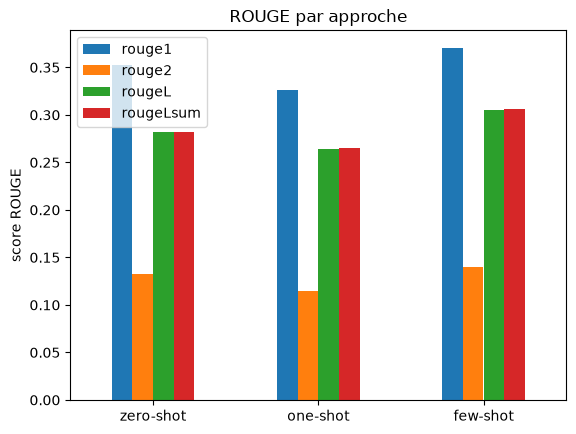

In [39]:
eval_set = dataset["test"].select(range(0, 60, 3))  # 20 dialogues distincts
eval_references = [dataset["test"][i:i + 3]["summary"] for i in range(0, 60, 3)]  # 3 références par dialogue

approaches = {
    "zero-shot": [],
    "one-shot": dataset["train"].select([0]),
    "few-shot": dataset["train"].select([0, 1, 2]),
}

summaries = {}
for name, shots in approaches.items():
    summaries[name] = [
        generate(make_messages(dialogue, shots), max_new_tokens=100, do_sample=False)
        for dialogue in eval_set["dialogue"]
    ]

few_shot_summaries = summaries["few-shot"]  # réutilisés dans la partie 8

scores = {
    name: rouge.compute(predictions=preds, references=eval_references)
    for name, preds in summaries.items()
}
df = pd.DataFrame(scores).T  # une ligne par approche, une colonne par score ROUGE
display(df)
df.plot.bar(rot=0, ylabel="score ROUGE", title="ROUGE par approche")
plt.show()

**Question** : quelle approche obtient les meilleurs scores ? Citez au moins deux limites de ROUGE.

✍️ **Votre réponse :**

Le few-shot obtient les meilleurs scores sur les quatre métriques :

| Approche | ROUGE-1 | ROUGE-2 | ROUGE-L | ROUGE-Lsum |
|---|---|---|---|---|
| zero-shot | 0.353 | 0.132 | 0.282 | 0.282 |
| one-shot | 0.326 | 0.115 | 0.265 | 0.265 |
| few-shot | **0.370** | **0.140** | **0.305** | **0.306** |

Le few-shot (3 exemples) est meilleur que le zero-shot, parce que les exemples montrent le style attendu (résumé court, `#Person1#`). Le one-shot fait pourtant moins bien que le zero-shot : un seul exemple ne suffit pas toujours, et le modèle peut trop s'y accrocher. Il faut donc plusieurs exemples pour que l'apport soit stable. Ces écarts restent petits et ont été mesurés sur seulement 20 dialogues, donc ils ne sont pas très fiables.

**Limites de ROUGE :**
- Il compte seulement les mots en commun. Un bon résumé qui reformule avec d'autres mots (synonymes, autre tournure) est pénalisé.
- Il ne vérifie ni le sens ni les faits : un résumé faux qui réutilise les bons mots peut avoir un bon score, et ROUGE ne détecte pas les informations inventées.
- Il dépend des références humaines choisies : plusieurs bons résumés différents existent, et le score varie selon celui qu'on prend.


## 7. Sorties structurées

Dans une application, on a rarement besoin de texte libre : on veut des **données exploitables** (pour remplir une base de données, appeler une API...). On demande alors au LLM de répondre en **JSON** respectant un schéma, que l'on valide avec [Pydantic](https://docs.pydantic.dev/).

Définissons le schéma des informations à extraire d'un dialogue.

In [40]:
from typing import Literal

from pydantic import BaseModel, Field, ValidationError


class DialogueInfo(BaseModel):
    topic: str = Field(description="Sujet principal du dialogue, en quelques mots")
    location: str = Field(description="Lieu où se déroule le dialogue, ou \"inconnu\" s'il n'est pas identifiable")
    action_items: list[str] = Field(description="Actions que les participants prévoient de faire")
    sentiment: Literal["positive", "neutral", "negative"] = Field(description="Ton général du dialogue")


def type_name(annotation):
    return annotation.__name__ if isinstance(annotation, type) else str(annotation).replace("typing.", "")


def describe_schema(schema):
    """Décrit les champs d'un modèle Pydantic, une ligne par champ (plus lisible qu'un schéma JSON pour un petit LLM)."""
    return "\n".join(
        f"- {name} ({type_name(field.annotation)}) : {field.description}" for name, field in schema.model_fields.items()
    )


print(describe_schema(DialogueInfo))

- topic (str) : Sujet principal du dialogue, en quelques mots
- location (str) : Lieu où se déroule le dialogue, ou "inconnu" s'il n'est pas identifiable
- action_items (list[str]) : Actions que les participants prévoient de faire
- sentiment (Literal['positive', 'neutral', 'negative']) : Ton général du dialogue


**Exercice 12** : compléter la fonction générique `generate_structured(messages, schema, max_retries=3)` qui :
1. ajoute au dernier message une consigne demandant de répondre uniquement en JSON avec les champs décrits par `describe_schema(schema)` ;
2. génère une réponse et extrait le JSON du texte (le modèle l'entoure parfois de balises Markdown) avec la fonction `extract_json` fournie ;
3. valide le JSON avec `schema.model_validate_json(...)`, qui lève une `ValidationError` en cas de problème ;
4. en cas d'erreur, ajoute la réponse fautive et le message d'erreur à la conversation, et redemande une correction au modèle, au plus `max_retries` fois. Attention : en décodage greedy, le modèle risque de reproduire exactement la même erreur. Pour les nouvelles tentatives, activez l'échantillonnage (`do_sample=True`).

<details>
<summary>💡 Indice 1 : ajouter la consigne sans modifier la liste reçue</summary>

Ne modifiez pas `messages` en place : la liste appartient à l'appelant. Construisez une nouvelle liste : tous les messages sauf le dernier (`messages[:-1]`), puis une copie du dernier message dont le contenu est complété. `{**message, "content": nouveau_contenu}` crée une copie d'un dictionnaire en remplaçant une clé.

</details>

<details>
<summary>💡 Indice 2 : le squelette</summary>

```
messages <- copie avec la consigne JSON ajoutée au dernier message
pour chaque tentative parmi max_retries :
    si ce n'est pas la première tentative :
        activer l'échantillonnage dans gen_kwargs
    raw <- generate(messages, ...)
    try:
        renvoyer schema.model_validate_json(extract_json(raw))
    except ValidationError as error:
        ajouter à messages la réponse fautive (rôle "assistant")
        puis un message "user" contenant l'erreur et demandant une correction
lever une ValueError : aucune tentative n'a abouti
```
Renvoyer la réponse fautive au modèle lui permet de « voir » son erreur dans la conversation. Levez bien une `ValueError` à la fin : l'exercice 13 s'appuie dessus.

</details>

<details>
<summary>💡 Indice 3 : détails Python</summary>

- `model_validate_json` lève une `ValidationError` aussi bien pour un JSON mal formé que pour un champ manquant ou du mauvais type.
- Pour activer l'échantillonnage sans modifier le dictionnaire de l'appelant : `gen_kwargs = {**gen_kwargs, "do_sample": True, "temperature": 0.7}`.
- La variable `error` du bloc `except` est effacée à la sortie de ce bloc : si vous voulez l'afficher dans la `ValueError` finale, conservez-la dans une autre variable.

</details>

In [41]:
def extract_json(text):
    """Extrait le premier objet JSON {...} d'un texte, en ignorant un éventuel bloc de raisonnement <think>...</think>."""
    text = text.rpartition("</think>")[2]
    match = re.search(r"\{.*\}", text, re.DOTALL)
    return match.group(0) if match else text


def generate_structured(messages, schema, max_retries=3, max_new_tokens=512, **gen_kwargs):
    """Génère une réponse validée par le modèle Pydantic `schema`."""
    instruction = (
        "\n\nRéponds uniquement avec un objet JSON valide, sans aucun autre texte, "
        f"avec les champs suivants :\n{describe_schema(schema)}"
    )
    messages = messages[:-1] + [{**messages[-1], "content": messages[-1]["content"] + instruction}]

    last_error = None
    for attempt in range(max_retries):
        if attempt > 0:
            gen_kwargs = {**gen_kwargs, "do_sample": True, "temperature": 0.7}

        raw = generate(messages, max_new_tokens=max_new_tokens, **gen_kwargs)
        try:
            return schema.model_validate_json(extract_json(raw))
        except ValidationError as error:
            last_error = error
            messages = messages + [
                {"role": "assistant", "content": raw},
                {"role": "user", "content": f"Ta réponse est invalide :\n{error}\nCorrige-la et réponds uniquement avec le JSON."},
            ]

    raise ValueError(f"Aucune réponse valide après {max_retries} tentatives. Dernière erreur : {last_error}")


info = generate_structured(
    [{"role": "user", "content": f"Extrais les informations de ce dialogue :\n\n{dataset['test'][40]['dialogue']}"}],
    DialogueInfo,
    do_sample=False,
)
info

DialogueInfo(topic='Heure et déplacement vers le train', location='inconnu', action_items=['prendre le train à 9h30', 'arriver à la gare en moins de 20 minutes'], sentiment='negative')

Appliquons l'extraction à plusieurs dialogues : nous obtenons directement une table, prête à être insérée dans une base de données.

In [42]:
rows = [
    generate_structured(
        [{"role": "user", "content": f"Extrais les informations de ce dialogue :\n\n{dialogue}"}],
        DialogueInfo,
        do_sample=False,
    ).model_dump()
    for dialogue in eval_set.select(range(5))["dialogue"]
]
pd.DataFrame(rows)

,topic,location,action_items,sentiment
0,Politique de restriction des communications,inconnu,[Écrire un membre inter-entreprise à tous les ...,negative
1,Transition vers le transport public et l'usage...,inconnu,"[utiliser le transport public, prendre la bicy...",negative
2,Divorce of Masha and Hero,inconnu,"[file for divorce, have a separation for 2 mon...",neutral
3,Fête de Brian,inconnu,"[danser avec Brian, boire un verre pour célébr...",positive
4,Olympic park and stadium,Olympic park,"[finish the stadium this June, provide English...",positive


**Remarque** : avec un petit modèle, donner le schéma JSON brut (`schema.model_json_schema()`) fonctionne mal : le modèle a tendance à recopier la structure du schéma (`{"properties": ...}`) au lieu de le remplir. Une description simple des champs donne de meilleurs résultats.

**Pour aller plus loin** : plutôt que de demander poliment au modèle de respecter le schéma et de réessayer en cas d'échec, les moteurs d'inférence actuels (vLLM, llama.cpp, Ollama, les API commerciales) proposent le **décodage contraint** : à chaque étape, les tokens qui rendraient le JSON invalide sont interdits (probabilité mise à zéro). La sortie est alors **garantie** conforme au schéma. Voir par exemple les bibliothèques [outlines](https://github.com/dottxt-ai/outlines) ou [xgrammar](https://github.com/mlc-ai/xgrammar).

## 8. LLM-as-a-judge

Une alternative à ROUGE : demander à un LLM d'évaluer les résumés selon une grille de critères. C'est aujourd'hui une pratique très répandue pour évaluer les applications à base de LLM.

**Exercice 13** : en utilisant `generate_structured`, écrire une fonction `judge(dialogue, summary)` qui renvoie un objet `Judgement` : une note de 1 à 5 évaluant la **fidélité** (pas d'information inventée ou fausse) et la **complétude** du résumé, accompagnée d'une justification. Appliquer cette fonction aux 20 résumés few-shot de la partie 6 et afficher la distribution des notes. Un LLM peut échouer : un échec sur un résumé ne doit pas interrompre toute l'évaluation (comptez les échecs).

<details>
<summary>💡 Indice 1 : la fonction judge</summary>

Deux lignes suffisent : remplir le gabarit avec `JUDGE_PROMPT.format(dialogue=..., summary=...)`, puis appeler `generate_structured` avec un seul message `user` et le schéma `Judgement` (en greedy pour la reproductibilité).

</details>

<details>
<summary>💡 Indice 2 : la boucle d'évaluation</summary>

- `zip(eval_set["dialogue"], few_shot_summaries)` parcourt les dialogues et leurs résumés en parallèle.
- Entourez l'appel à `judge` d'un `try` / `except ValueError` et comptez les échecs.
- Distribution des notes : `pd.Series(notes).value_counts().sort_index().plot.bar()`.
- `few_shot_summaries` n'existe plus si la session a redémarré : relancez l'exercice 11.

</details>

20 notes, 0 échec(s) | note moyenne : 4.25


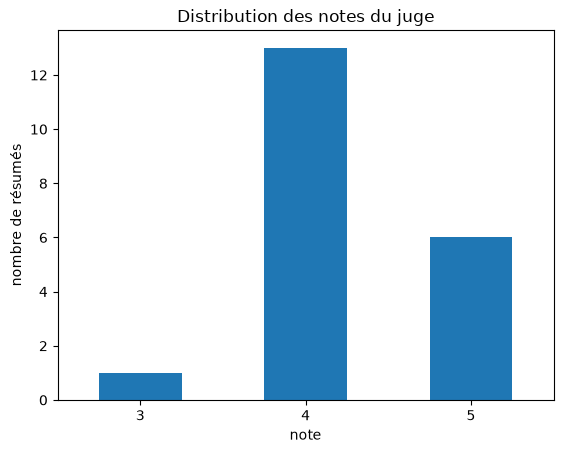

In [43]:
class Judgement(BaseModel):
    # La justification est demandée AVANT la note : le modèle « raisonne » avant de conclure.
    justification: str = Field(description="Justification de la note en une ou deux phrases")
    score: int = Field(ge=1, le=5, description="Note de 1 (mauvais) à 5 (excellent)")


JUDGE_PROMPT = """Tu évalues la qualité du résumé d'un dialogue.
Critères : fidélité (aucune information inventée ou fausse) et complétude (les points clés sont présents).

DIALOGUE :
{dialogue}

RÉSUMÉ À ÉVALUER :
{summary}"""


def judge(dialogue, summary):
    """Note un résumé de 1 à 5 (fidélité et complétude), avec une justification."""
    prompt = JUDGE_PROMPT.format(dialogue=dialogue, summary=summary)
    return generate_structured([{"role": "user", "content": prompt}], Judgement, do_sample=False)


judgements, failures = [], 0
for dialogue, summary in zip(eval_set["dialogue"], few_shot_summaries):
    try:
        judgements.append(judge(dialogue, summary))
    except ValueError:
        failures += 1 

notes = [j.score for j in judgements]
print(f"{len(notes)} notes, {failures} échec(s) | note moyenne : {sum(notes) / len(notes):.2f}")

pd.Series(notes).value_counts().sort_index().plot.bar(rot=0, xlabel="note", ylabel="nombre de résumés", title="Distribution des notes du juge")
plt.show()

**Question** : peut-on faire confiance à ce juge ? Citez des biais connus des LLM juges. Comment vérifier la fiabilité d'un juge ?

✍️ **Votre réponse :**

On ne peut pas lui faire entièrement confiance. Sur nos 20 résumés, le juge n'a mis aucune note inférieure à 3 (13 notes de 4, 6 notes de 5, 1 note de 3, moyenne 4,25). Il est donc très indulgent et peu discriminant : il sépare mal les bons résumés des moyens. De plus, le juge est le même petit modèle (Qwen3-1.7B) que celui qui a généré les résumés, donc il peut valider ses propres erreurs.

**Biais connus des LLM juges :**
- **Biais d'auto-préférence** : un modèle note mieux les textes qui ressemblent à ce qu'il produit lui-même.
- **Biais de longueur** : les résumés longs et détaillés sont souvent mieux notés, même s'ils sont moins bons.
- **Biais de position** : quand on compare deux réponses, le juge favorise souvent la première.
- **Indulgence** : les notes se concentrent sur les valeurs hautes, comme ici.

**Vérifier la fiabilité d'un juge :**
- Comparer ses notes à des notes humaines sur un échantillon (corrélation, taux d'accord).
- Utiliser un juge plus puissant et différent du modèle évalué (API gratuite, modèle plus gros).
- Tester sur des cas connus : un résumé volontairement faux ou hors sujet doit obtenir une mauvaise note.
- Vérifier la stabilité : relancer avec d'autres graines ou un autre ordre et voir si les notes changent.

### Annexe : utiliser une API gratuite (optionnel)

Pour obtenir un juge plus puissant et **différent** du modèle évalué, vous pouvez utiliser une API offrant un accès gratuit (avec des limites de débit). La plupart sont compatibles avec le client `openai`, ce qui permet de changer de fournisseur en changeant seulement `base_url` et `model` :

| Fournisseur | Inscription | `base_url` |
|---|---|---|
| Google AI Studio (Gemini) | https://aistudio.google.com | `https://generativelanguage.googleapis.com/v1beta/openai/` |
| Groq | https://console.groq.com | `https://api.groq.com/openai/v1` |
| OpenRouter (modèles `:free`) | https://openrouter.ai | `https://openrouter.ai/api/v1` |
| Ollama (local, sur votre machine) | https://ollama.com | `http://localhost:11434/v1` |

Les noms des modèles et les quotas gratuits changent souvent : consultez la documentation du fournisseur (ou `client.models.list()`).

**Règles** :
- ne jamais écrire une clé d'API en clair dans un notebook : utilisez les **Secrets** de Colab (icône 🔑 dans la barre latérale), lus avec `userdata.get(...)` ;
- les offres gratuites peuvent utiliser vos données pour entraîner leurs modèles : n'envoyez **aucune donnée personnelle ou confidentielle**.

In [ ]:
# %pip install -q openai
# from google.colab import userdata
# from openai import OpenAI
#
# client = OpenAI(base_url="https://api.groq.com/openai/v1", api_key=userdata.get("GROQ_API_KEY"))
# response = client.chat.completions.create(
#     model="openai/gpt-oss-20b",  # à adapter : voir la liste des modèles du fournisseur
#     messages=[{"role": "user", "content": "Bonjour !"}],
# )
# print(response.choices[0].message.content)

## Bonus : quantification

Les poids d'un modèle sont stockés en float16 (2 octets par paramètre) : un modèle de 8 milliards de paramètres occupe donc environ 16 Go, trop pour le T4. La **quantification** stocke les poids sur moins de bits (8, 4, voire moins) au prix d'une légère perte de qualité. C'est ce qui permet d'exécuter des modèles sur un ordinateur portable (format GGUF avec llama.cpp, Ollama ou LM Studio).

La cellule ci-dessous charge [Qwen3-8B](https://huggingface.co/Qwen/Qwen3-8B) quantifié en 4 bits avec `bitsandbytes`. Elle télécharge 16 Go : exécutez-la seulement si vous avez le temps, après avoir libéré le modèle actuel.

**Question** : comparez la mémoire occupée et la qualité des résumés avec le modèle 1.7B.

In [ ]:
# %pip install -q bitsandbytes
# from transformers import BitsAndBytesConfig
#
# del model
# gc.collect()
# torch.cuda.empty_cache()
#
# quantization_config = BitsAndBytesConfig(
#     load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16
# )
# MODEL_NAME = "Qwen/Qwen3-8B"
# tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
# model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=quantization_config, device_map="auto")
# print(f"Mémoire occupée par le modèle : {model.get_memory_footprint() / 1e9:.1f} Go")

## Mini-projet (au choix)

**Durée estimée** : 3-4 heures. Choisissez **un** des deux sujets. Ils ne demandent que les notions vues dans ce TP.

**Livrables attendus** (pour les deux sujets) :
- code documenté, factorisé (réutilisez `generate`, `generate_structured`...) ;
- une évaluation **quantitative** sur un jeu de test annoté, avec une comparaison de plusieurs approches ;
- une analyse en markdown : ce qui fonctionne, ce qui échoue et pourquoi, pistes d'amélioration.

Pour comparer, vous pouvez utiliser un modèle plus gros qui tient aussi sur le T4, comme [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) (environ 8 Go en float16, sans mode raisonnement). Pensez à libérer la mémoire du modèle précédent (`del model`, `gc.collect()`, `torch.cuda.empty_cache()`) avant de le charger.

### Sujet A : du texte brut à une base de données

Beaucoup de données utiles n'existent que sous forme de texte libre : annonces, comptes rendus, courriels, CV... Un LLM peut les **structurer** pour alimenter une base de données. Mais peut-on faire confiance aux données qu'il produit ?

1. Constituer un corpus d'une vingtaine de textes courts d'un même type (par exemple des annonces immobilières : *« Vends T3 de 68 m² à Poitiers, balcon, 189 000 € »*). Variez les formulations et prévoyez des pièges : informations absentes, plusieurs prix ou surfaces dans le même texte, abréviations (`T3`, `k€`, `CC`), négations (*« sans balcon »*).
2. Définir le schéma cible avec Pydantic (types, `Literal`, champs pouvant valoir `None`) et la table SQLite correspondante, avec des contraintes (`NOT NULL`, `CHECK`).
3. Annoter **à la main** au moins 15 textes : c'est votre vérité terrain.
4. Extraire les données avec `generate_structured`, puis les insérer dans la base avec le module `sqlite3`.
5. Mesurer l'**exactitude champ par champ** par rapport à la vérité terrain, et comparer plusieurs approches : zero-shot, few-shot (exemples d'annonces avec le JSON attendu), mode raisonnement activé, et éventuellement un modèle plus gros.
6. Écrire quelques requêtes SQL d'analyse (prix moyen par type de bien, prix au m²...) et comparer leurs résultats sur les données extraites et sur la vérité terrain.

**Questions** : quels champs sont les plus mal extraits, et pourquoi ? Quelles erreurs du LLM faussent le plus les agrégats ? Que se passe-t-il quand le modèle invente une valeur au lieu de renvoyer `null` ? Quels contrôles ajouteriez-vous avant d'insérer des données produites par un LLM dans une base de production ?

### Sujet B : classification par les probabilités

Pour classer un texte, on peut laisser le LLM **générer** le label, ou bien **lire directement** dans la distribution du token suivant (partie 2) la probabilité de chaque label. La seconde approche donne un score de confiance, et pas seulement une réponse.

Travaillez sur la polarité de critiques de films en français, avec le dataset [allocine](https://huggingface.co/datasets/tblard/allocine) (`load_dataset("tblard/allocine")`, label 0 = négatif, 1 = positif). Utilisez un échantillon **équilibré** d'environ 200 critiques du split `test`, tronquées si elles sont trop longues.

1. **Approche générative** : avec un system prompt adapté, faire générer `positif` ou `négatif`, analyser la réponse et compter les réponses invalides.
2. **Approche par les probabilités** : appliquer le chat template, faire **un seul** passage dans le modèle et comparer la probabilité du premier token de `positif` et de `négatif`. En déduire un score $P(\text{positif}) / (P(\text{positif}) + P(\text{négatif}))$.
3. Évaluer les deux approches : exactitude, matrice de confusion, temps de calcul ; et pour l'approche par les probabilités, l'aire sous la courbe ROC.
4. Étudier l'effet du **nombre d'exemples** few-shot (0, 2, 4, 8 exemples pris dans le split `validation`) et de leur **ordre** (tous les exemples positifs d'abord, ou tous les négatifs d'abord).
5. Étudier le **calibrage** : quand le modèle est sûr à 90 %, a-t-il raison 90 % du temps ? Tracer l'exactitude en fonction de la confiance (*reliability diagram*).

**Questions** : le modèle a-t-il un biais vers l'un des labels ? Le seuil de 0,5 est-il le bon ? Quels avantages pratiques l'approche par les probabilités présente-t-elle (coût, réponses invalides, possibilité de s'abstenir quand le modèle hésite) ? Quelles critiques sont mal classées, et pourquoi (ironie, critiques nuancées...) ?


**Étape 0 : préparer l’échantillon équilibré**

In [44]:
from datasets import concatenate_datasets

allocine = load_dataset("tblard/allocine")
test = allocine["test"].shuffle(seed=42)

# 100 critiques positives + 100 négatives, tronquées à 1000 caractères
half = 100
sample = concatenate_datasets([
    test.filter(lambda x: x["label"] == 1).select(range(half)),
    test.filter(lambda x: x["label"] == 0).select(range(half)),
]).shuffle(seed=42)
sample = sample.map(lambda x: {"review": x["review"][:1000]})

reviews, labels = sample["review"], sample["label"]
print(len(sample), "critiques | positives :", sum(labels))

allocine/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 60.0MB            

allocine/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

allocine/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 7.58MB            

allocine/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

allocine/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 7.58MB            

allocine/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (3 outputs left out)

Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

200 critiques | positives : 100


**Étape 1 : approche générative**

In [45]:
CLASSIF_PROMPT = (
    "Tu classes la polarité de critiques de films. "
    "Réponds uniquement par un seul mot : positif ou négatif."
)


def classify_generative(review):
    """Fait générer le label au modèle. Renvoie 1 (positif), 0 (négatif) ou None (réponse invalide)."""
    messages = [
        {"role": "system", "content": CLASSIF_PROMPT},
        {"role": "user", "content": review},
    ]
    answer = generate(messages, max_new_tokens=5, do_sample=False).lower()
    if "positif" in answer:
        return 1
    if "négatif" in answer or "negatif" in answer:
        return 0
    return None  # réponse invalide


start = time.perf_counter()
preds_gen = [classify_generative(review) for review in reviews]
time_gen = time.perf_counter() - start

invalid = sum(p is None for p in preds_gen)
accuracy = sum(p == y for p, y in zip(preds_gen, labels)) / len(labels)
print(f"Réponses invalides : {invalid} | exactitude : {accuracy:.3f} | temps : {time_gen:.0f} s")

Réponses invalides : 2 | exactitude : 0.905 | temps : 135 s


**Étape 2 : approche par les probabilités**

On applique le même prompt, puis on fait un seul passage dans le modèle. On lit la probabilité du premier token de `positif` et de `négatif` dans la distribution du token suivant, avec `next_token_distribution`.

In [46]:
pos_id = tokenizer.encode("positif", add_special_tokens=False)[0]
neg_id = tokenizer.encode("négatif", add_special_tokens=False)[0]
print("positif ->", repr(tokenizer.decode(pos_id)), "| négatif ->", repr(tokenizer.decode(neg_id)))
assert pos_id != neg_id, "Les deux labels commencent par le même token"


def score_positive(review):
    """Renvoie P(positif) / (P(positif) + P(négatif)) avec un seul passage dans le modèle."""
    messages = [
        {"role": "system", "content": CLASSIF_PROMPT},
        {"role": "user", "content": review},
    ]
    prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    probs = next_token_distribution(prompt)
    p_pos, p_neg = probs[pos_id].item(), probs[neg_id].item()
    return p_pos / (p_pos + p_neg)


start = time.perf_counter()
scores = [score_positive(review) for review in reviews]
time_prob = time.perf_counter() - start

preds_prob = [int(s > 0.5) for s in scores]
accuracy = sum(p == y for p, y in zip(preds_prob, labels)) / len(labels)
print(f"Exactitude : {accuracy:.3f} | temps : {time_prob:.0f} s | aucune réponse invalide")

positif -> 'posit' | négatif -> 'n'
Exactitude : 0.915 | temps : 96 s | aucune réponse invalide


**Étape 3 : évaluation**

Approche générative :


prédit,invalide,négatif,positif
réel,,,
négatif,0,86,14
positif,2,3,95


Approche par les probabilités :


prédit,négatif,positif
réel,,
négatif,86,14
positif,3,97


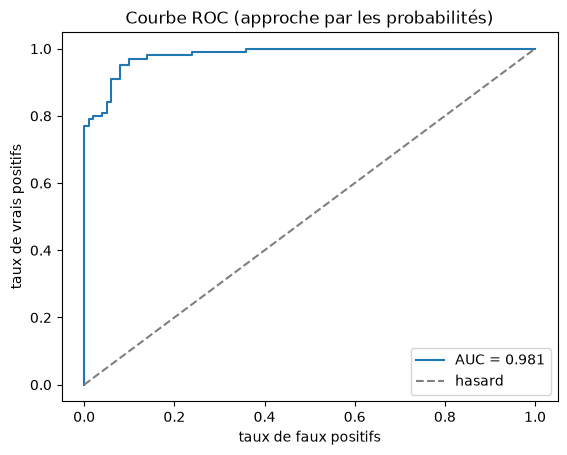

,exactitude,réponses invalides,temps (s)
générative,0.905,2,135
probabilités,0.915,0,96


In [47]:
import numpy as np

names = {0: "négatif", 1: "positif"}


def confusion(preds):
    """Matrice de confusion ; les réponses invalides (None) ont leur propre colonne."""
    real = pd.Series([names[y] for y in labels], name="réel")
    pred = pd.Series(["invalide" if p is None else names[p] for p in preds], name="prédit")
    return pd.crosstab(real, pred)


print("Approche générative :")
display(confusion(preds_gen))
print("Approche par les probabilités :")
display(confusion(preds_prob))


def roc_auc(y_true, y_score):
    """Courbe ROC et aire sous la courbe (AUC)."""
    y_true, y_score = np.array(y_true), np.array(y_score)
    y_sorted = y_true[np.argsort(-y_score)]
    tpr = np.concatenate([[0], np.cumsum(y_sorted) / y_sorted.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y_sorted) / (1 - y_sorted).sum()])
    auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)
    return fpr, tpr, auc


fpr, tpr, auc = roc_auc(labels, scores)
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray", label="hasard")
plt.xlabel("taux de faux positifs")
plt.ylabel("taux de vrais positifs")
plt.title("Courbe ROC (approche par les probabilités)")
plt.legend()
plt.show()

summary = pd.DataFrame({
    "exactitude": [
        sum(p == y for p, y in zip(preds_gen, labels)) / len(labels),
        sum(p == y for p, y in zip(preds_prob, labels)) / len(labels),
    ],
    "réponses invalides": [sum(p is None for p in preds_gen), 0],
    "temps (s)": [round(time_gen), round(time_prob)],
}, index=["générative", "probabilités"])
display(summary)

**Étape 4 : nombre et ordre des exemples few-shot**

In [48]:
val = allocine["validation"].shuffle(seed=0)
pos_pool = list(val.filter(lambda x: x["label"] == 1).select(range(4)))
neg_pool = list(val.filter(lambda x: x["label"] == 0).select(range(4)))
LABEL_TEXT = {0: "négatif", 1: "positif"}


def get_shots(n, order="alterné"):
    """n exemples équilibrés (n/2 positifs, n/2 négatifs), dans l'ordre demandé."""
    pos, neg = pos_pool[: n // 2], neg_pool[: n // 2]
    if order == "positifs d'abord":
        return pos + neg
    if order == "négatifs d'abord":
        return neg + pos
    return [x for pair in zip(pos, neg) for x in pair]  # alterné


def score_with_shots(review, shots):
    messages = [{"role": "system", "content": CLASSIF_PROMPT}]
    for shot in shots:
        messages.append({"role": "user", "content": shot["review"][:500]})
        messages.append({"role": "assistant", "content": LABEL_TEXT[shot["label"]]})
    messages.append({"role": "user", "content": review})
    prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    probs = next_token_distribution(prompt)
    p_pos, p_neg = probs[pos_id].item(), probs[neg_id].item()
    return p_pos / (p_pos + p_neg)


def evaluate_shots(shots, n_eval=len(reviews)):
    start = time.perf_counter()
    s = [score_with_shots(review, shots) for review in reviews[:n_eval]]
    elapsed = time.perf_counter() - start
    preds = [int(x > 0.5) for x in s]
    return {
        "exactitude": sum(p == y for p, y in zip(preds, labels)) / n_eval,
        "% prédits positifs": sum(preds) / n_eval,  # 0.5 attendu sur un échantillon équilibré
        "AUC": roc_auc(labels[:n_eval], s)[2],
        "temps (s)": round(elapsed),
    }


# 1. Effet du nombre d'exemples (ordre alterné)
results = {f"{n} exemples": evaluate_shots(get_shots(n)) for n in [0, 2, 4, 8]}
df_n = pd.DataFrame(results).T
display(df_n)

# 2. Effet de l'ordre (8 exemples)
results = {order: evaluate_shots(get_shots(8, order)) for order in ["alterné", "positifs d'abord", "négatifs d'abord"]}
df_order = pd.DataFrame(results).T
display(df_order)

Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]

,exactitude,% prédits positifs,AUC,temps (s)
0 exemples,0.915,0.555,0.9809,94.0
2 exemples,0.900,0.550,0.9789,158.0
4 exemples,0.910,0.540,0.9794,200.0
8 exemples,0.900,0.570,0.9753,414.0


,exactitude,% prédits positifs,AUC,temps (s)
alterné,0.90,0.57,0.9753,412.0
positifs d'abord,0.89,0.58,0.9687,413.0
négatifs d'abord,0.91,0.58,0.9821,412.0


**Étape 4 : nombre et ordre des exemples**

| Configuration | Exactitude | % prédits positifs | AUC | Temps (s) |
|---|---|---|---|---|
| 0 exemple | 0.915 | 0.555 | 0.981 | 94 |
| 2 exemples | 0.900 | 0.550 | 0.979 | 158 |
| 4 exemples | 0.910 | 0.540 | 0.979 | 200 |
| 8 exemples | 0.900 | 0.570 | 0.975 | 414 |

| Ordre (8 exemples) | Exactitude | % prédits positifs | AUC |
|---|---|---|---|
| alterné | 0.90 | 0.57 | 0.975 |
| positifs d'abord | 0.89 | 0.58 | 0.969 |
| négatifs d'abord | 0.91 | 0.58 | 0.982 |

- **Nombre d'exemples** : les exemples n'apportent aucun gain. L'exactitude reste autour de 0,90-0,915 et l'AUC baisse même légèrement (0,981 à 0,975). En revanche, le temps est multiplié par 4,4 (94 s à 414 s), car le prompt est plus long. La tâche est simple et le modèle la comprend déjà avec le system prompt seul.
- **Biais** : le modèle prédit « positif » plus souvent que les 50 % attendus (54 à 58 %), quel que soit le nombre d'exemples. Les exemples ne corrigent pas ce biais.
- **Ordre** : l'ordre a un effet faible : l'exactitude varie de 0,89 à 0,91 et l'AUC de 0,969 à 0,982. Ces écarts correspondent à 2 à 4 critiques sur 200 : ils sont proches du bruit de mesure, donc on ne peut pas conclure avec certitude. Le meilleur ordre ici est « négatifs d'abord » et le pire « positifs d'abord ».

**Étape 5 : calibrage et seuil**

,tranche,n,confiance moy.,exactitude
0,0.5-0.6,3,0.524717,0.000000
1,0.7-0.8,2,0.732456,0.500000
2,0.8-0.9,2,0.851581,0.500000
3,0.9-1.0,193,0.998511,0.937824


ECE (erreur de calibrage moyenne) : 0.072


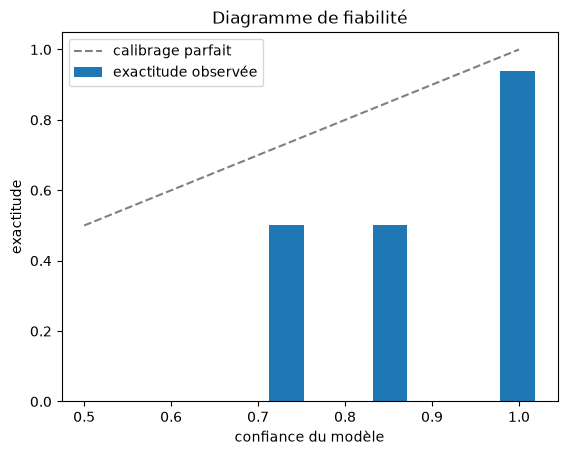

Exactitude à 0.5 : 0.915 | meilleur seuil : 0.90 (0.935)
confiance ≥ 0.6 : 98% des critiques traitées, exactitude 0.929
confiance ≥ 0.7 : 98% des critiques traitées, exactitude 0.929
confiance ≥ 0.8 : 98% des critiques traitées, exactitude 0.933
confiance ≥ 0.9 : 96% des critiques traitées, exactitude 0.938


In [49]:
scores_arr = np.array(scores)
labels_arr = np.array(labels)
preds_arr = (scores_arr > 0.5).astype(int)

# Confiance du modèle dans sa prédiction : entre 0.5 et 1
confidence = np.maximum(scores_arr, 1 - scores_arr)
correct = (preds_arr == labels_arr)

# Diagramme de fiabilité : exactitude observée par tranche de confiance
bins = np.linspace(0.5, 1.0, 6)
bin_ids = np.clip(np.digitize(confidence, bins) - 1, 0, len(bins) - 2)
rows, ece = [], 0
for b in range(len(bins) - 1):
    mask = bin_ids == b
    if mask.sum() == 0:
        continue
    acc, conf = correct[mask].mean(), confidence[mask].mean()
    ece += mask.mean() * abs(acc - conf)  # erreur de calibrage attendue (ECE)
    rows.append({"tranche": f"{bins[b]:.1f}-{bins[b + 1]:.1f}", "n": int(mask.sum()), "confiance moy.": conf, "exactitude": acc})
display(pd.DataFrame(rows))
print(f"ECE (erreur de calibrage moyenne) : {ece:.3f}")

df_cal = pd.DataFrame(rows)
plt.bar(df_cal["confiance moy."], df_cal["exactitude"], width=0.04, label="exactitude observée")
plt.plot([0.5, 1], [0.5, 1], "--", color="gray", label="calibrage parfait")
plt.xlabel("confiance du modèle")
plt.ylabel("exactitude")
plt.title("Diagramme de fiabilité")
plt.legend()
plt.show()

# Le seuil de 0.5 est-il le bon ?
thresholds = np.linspace(0.05, 0.95, 19)
accs = [((scores_arr > t).astype(int) == labels_arr).mean() for t in thresholds]
best = thresholds[int(np.argmax(accs))]
print(f"Exactitude à 0.5 : {accs[9]:.3f} | meilleur seuil : {best:.2f} ({max(accs):.3f})")

# Abstention : on ne répond que si le modèle est sûr
for t in [0.6, 0.7, 0.8, 0.9]:
    mask = confidence >= t
    print(f"confiance ≥ {t} : {mask.mean():.0%} des critiques traitées, exactitude {correct[mask].mean():.3f}")

**Étape 5 : calibrage**

| Tranche de confiance | n | Confiance moyenne | Exactitude |
|---|---|---|---|
| 0.5-0.6 | 3 | 0.525 | 0.000 |
| 0.7-0.8 | 2 | 0.732 | 0.500 |
| 0.8-0.9 | 2 | 0.852 | 0.500 |
| 0.9-1.0 | 193 | 0.999 | 0.938 |

ECE = 0.072.

- **Le modèle est trop sûr de lui** : 193 critiques sur 200 reçoivent une confiance supérieure à 0,9 (en moyenne 99,9 %), mais l'exactitude dans cette tranche n'est que de 93,8 %. Les barres sont toutes sous la diagonale du calibrage parfait. Quand le modèle dit 99,9 %, il se trompe encore environ 6 fois sur 100.
- **La confiance sert quand même de signal** : les rares critiques où le modèle hésite (confiance inférieure à 0,9) sont en majorité mal classées (2 bonnes réponses sur 7). Mais les tranches faibles ne contiennent que 2 ou 3 critiques : on ne peut pas en tirer de conclusion fiable.
- **Seuil** : le seuil de 0,5 n'est pas optimal. Un seuil de 0,90 donne 0,935 d'exactitude contre 0,915 (+2 points), ce qui corrige en partie le biais vers « positif ». Ce seuil a été choisi sur le même échantillon que l'évaluation : le gain est donc probablement optimiste. Il faudrait le choisir sur le split `validation` puis le tester sur `test`.
- **Abstention** : s'abstenir quand la confiance est faible apporte peu ici : à 0,9, on traite 96 % des critiques avec 93,8 % d'exactitude (contre 91,5 % au total), parce que le modèle est presque toujours très confiant.

In [50]:
errors = np.where(~correct)[0]
# Les erreurs où le modèle était le plus sûr de lui d'abord
errors = sorted(errors, key=lambda i: -confidence[i])
for i in errors[:8]:
    print(f"réel : {names[labels[i]]} | prédit : {names[preds_arr[i]]} | confiance : {confidence[i]:.3f}")
    print(reviews[i][:300], "\n" + "-" * 80)

réel : positif | prédit : négatif | confiance : 1.000
comment une critique peut être pertinente quand sa photo de profil est le choc des titans et que son commentaire est truffé de fautes. scarface772 
--------------------------------------------------------------------------------
réel : négatif | prédit : positif | confiance : 1.000
C'est un film. Il y a du rouge. Une jolie actrice qui a l'air tarte pendant tout le film, dont la vie lui échappe totalement, elle a au moins l'honnêteté de ne pas prétendre comprendre et maîtriser. La vie tourne autour d'elle, sans qu'elle puisse vraiment faire autre chose que la potiche, ce qui es 
--------------------------------------------------------------------------------
réel : négatif | prédit : positif | confiance : 1.000
Un film d'aventure polaire destiné essentiellement aux plus jeunes ! 
--------------------------------------------------------------------------------
réel : négatif | prédit : positif | confiance : 1.000
On ne retiendra, de c

**Réponses aux questions**

- **Biais vers un label** : oui, le modèle est biaisé vers « positif ». Il prédit « positif » pour 55,5 % des critiques alors que l'échantillon est équilibré à 50 %. Il classe 14 critiques négatives en positif contre seulement 3 critiques positives en négatif.
- **Le seuil de 0,5 est-il le bon ?** Non : un seuil de 0,90 donne 0,935 d'exactitude contre 0,915. Il compense le biais vers « positif ». Il faudrait le choisir sur un jeu de validation séparé pour ne pas surestimer le gain.
- **Avantages de l'approche par les probabilités** :
  - *Coût* : un seul passage dans le modèle, sans génération. Elle est plus rapide (96 s contre 135 s pour 200 critiques).
  - *Pas de réponse invalide* : 0 contre 2 pour l'approche générative, car on lit toujours un score entre 0 et 1, sans analyser un texte.
  - *Score de confiance* : on obtient un score continu (AUC de 0,981), pas seulement un label, et on peut régler le seuil ou s'abstenir quand le modèle hésite.
  - *Limite* : le score est mal calibré (trop sûr de lui, ECE = 0,072), et la probabilité du token `n` (début de « négatif ») est un peu bruitée, car ce token est très générique.
- **Critiques mal classées** : le modèle se trompe avec une confiance de 1,000, donc il n'hésite même pas. Les erreurs montrent plusieurs causes :
  - *Ironie et sarcasme* : « C'est un film. Il y a du rouge. Une jolie actrice qui a l'air tarte pendant tout le film... » est une critique négative, mais le ton ironique et les mots comme « jolie » ou « honnêteté » trompent le modèle.
  - *Critiques nuancées* : « On ne retiendra de ce film lent et sans profondeur que la performance extraordinaire de Jennifer Aniston ! » mélange des reproches (lent, sans profondeur) et un compliment. Le modèle ne retient que le compliment, alors que la note globale est négative. Même chose pour « Cette comédie ne marquera pas l'histoire du cinéma, mais elle fait passer un bon moment ».
  - *Critiques sans avis clair* : « Un film d'aventure polaire destiné essentiellement aux plus jeunes ! » décrit le film sans juger. Le modèle conclut « positif » sans preuve, ce qui confirme son biais vers ce label.
  - *Critiques hors sujet ou mal étiquetées* : « Comment une critique peut être pertinente quand sa photo de profil est Le Choc des titans... » parle d'un autre commentateur, pas du film. Le label « positif » est donc discutable (bruit dans les données), et c'est le seul cas où l'erreur vient peut-être du dataset plutôt que du modèle.